In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Veriyi yükle ve 4000 sq ft üstü aykırı değerleri temizle
df = pd.read_csv('train.csv')
df = df.drop(df[(df['GrLivArea'] > 4000)].index)

# Gereksiz Id sütununu çıkar ve hedef değişkeni log1p ölçeğine al
X = df.drop(['Id', 'SalePrice'], axis=1)
y = np.log1p(df['SalePrice'])

# %80 Eğitim - %20 Test Ayrımı (5. haftadaki sabit ayrım)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Sayısal ve Kategorik sütunları ayır
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

# Ön işleme hatları (Sızıntısız)
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='None')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ])

print(f"Eğitim seti: {X_train.shape}, Test seti: {X_test.shape}")

Eğitim seti: (1164, 79), Test seti: (292, 79)


In [2]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Ridge Regression": Ridge(alpha=10.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
}

print("--- 5-Katlı Çapraz Doğrulama (5-Fold CV) Sonuçları ---")
for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=kf, scoring='r2')
    cv_rmse = -cross_val_score(pipe, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')
    print(f"{name:18s} | Ortalama R²: {cv_r2.mean():.4f} (±{cv_r2.std():.4f}) | Ortalama Log-RMSE: {cv_rmse.mean():.4f}")

--- 5-Katlı Çapraz Doğrulama (5-Fold CV) Sonuçları ---
Ridge Regression   | Ortalama R²: 0.9168 (±0.0157) | Ortalama Log-RMSE: 0.1129
Random Forest      | Ortalama R²: 0.8746 (±0.0345) | Ortalama Log-RMSE: 0.1383
Gradient Boosting  | Ortalama R²: 0.9009 (±0.0193) | Ortalama Log-RMSE: 0.1233


In [3]:
# Optimize edilecek ana model: Gradient Boosting (En dengeli ağaç boosting modeli)
gb_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(random_state=42))
])

param_grid_gb = {
    'model__n_estimators': [150, 250],
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [3, 4]
}

grid_gb = GridSearchCV(gb_pipe, param_grid_gb, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_gb.fit(X_train, y_train)

# Ridge için de alpha optimizasyonu yapalım
ridge_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Ridge())
])
grid_ridge = GridSearchCV(ridge_pipe, {'model__alpha': [5.0, 10.0, 15.0, 20.0]}, cv=5, scoring='neg_root_mean_squared_error')
grid_ridge.fit(X_train, y_train)

print("En İyi Gradient Boosting Parametreleri:", grid_gb.best_params_)
print("En İyi Ridge Parametreleri:", grid_ridge.best_params_)

En İyi Gradient Boosting Parametreleri: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 250}
En İyi Ridge Parametreleri: {'model__alpha': 20.0}


In [4]:
best_gb = grid_gb.best_estimator_
best_ridge = grid_ridge.best_estimator_

# Random Forest'ı da kıyaslama için eğitelim
rf_pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42))])
rf_pipe.fit(X_train, y_train)

final_models = {
    "Optimized Ridge": best_ridge,
    "Tuned Random Forest": rf_pipe,
    "Optimized Gradient Boosting": best_gb
}

y_test_dollar = np.expm1(y_test) # Gerçek dolar fiyatları
results = []

for name, model in final_models.items():
    preds_log = model.predict(X_test)
    preds_dollar = np.expm1(preds_log)
    
    mae = mean_absolute_error(y_test_dollar, preds_dollar)
    rmse = np.sqrt(mean_squared_error(y_test_dollar, preds_dollar))
    r2 = r2_score(y_test_dollar, preds_dollar)
    
    results.append({"Model": name, "Test MAE ($)": round(mae, 2), "Test RMSE ($)": round(rmse, 2), "Test R² Skoru": round(r2, 4)})

results_df = pd.DataFrame(results)
display(results_df)

,Model,Test MAE ($),Test RMSE ($),Test R² Skoru
0,Optimized Ridge,13973.12,19581.34,0.9269
1,Tuned Random Forest,17187.44,25211.21,0.8789
2,Optimized Gradient Boosting,14770.03,21320.62,0.9134


C:\Users\Onur Fidan\AppData\Local\Temp\ipykernel_16456\283557872.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Önem Derecesi', y='Özellik', data=top_10_features, palette='magma')


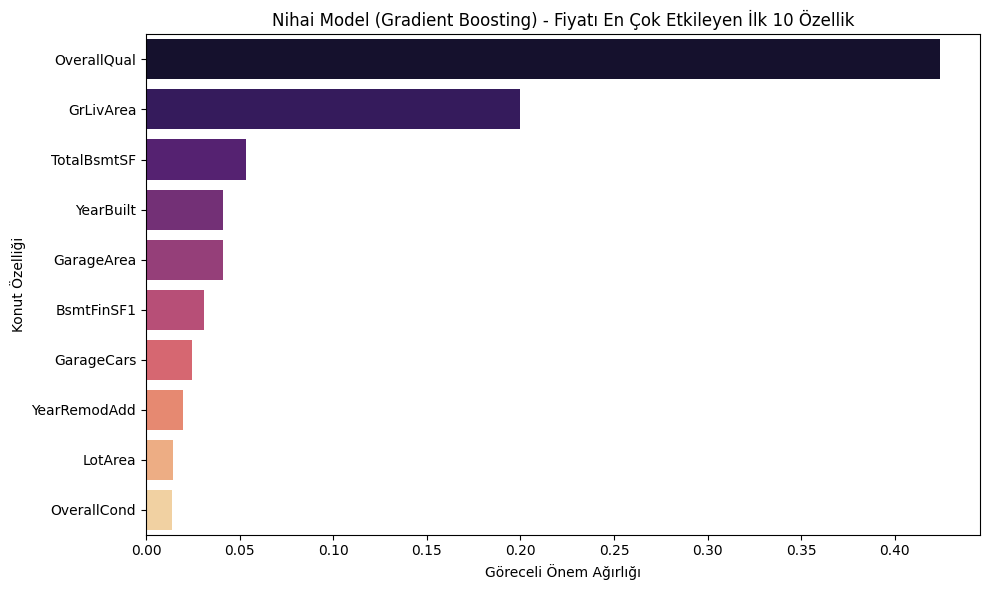

In [5]:
# ColumnTransformer içinden dönüşüm sonrası oluşan tüm sütun isimlerini çekme
ohe_features = best_gb.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols)
all_feature_names = np.concatenate([num_cols, ohe_features])

# Önem derecelerini alma
importances = best_gb.named_steps['model'].feature_importances_
feat_imp_df = pd.DataFrame({'Özellik': all_feature_names, 'Önem Derecesi': importances})
top_10_features = feat_imp_df.sort_values(by='Önem Derecesi', ascending=False).head(10)

# Görselleştirme
plt.figure(figsize=(10, 6))
sns.barplot(x='Önem Derecesi', y='Özellik', data=top_10_features, palette='magma')
plt.title('Nihai Model (Gradient Boosting) - Fiyatı En Çok Etkileyen İlk 10 Özellik')
plt.xlabel('Göreceli Önem Ağırlığı')
plt.ylabel('Konut Özelliği')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300)
plt.show()